**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [ ]:
# Імпортуйте необхідні бібліотеки
# За потреби встановлюємо prophet та pmdarima (в Colab)
!pip install prophet pmdarima -q

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from prophet import Prophet
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
)
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

In [ ]:
# Завантажте датасет з Kaggle
csv_filename = "kaggle_weather_2013_to_2024.csv"

In [ ]:
# Зчитайте датасет у DataFrame та перегляньте дані
csv_filename = "/content/kaggel_weather_2013_to_2024.csv"

df = pd.read_csv(csv_filename)

print("--- Перші 5 рядків (head) ---")
display(df.head())

print("\n--- Інформація про датасет (info) ---")
df.info()

print("\n--- Описова статистика (describe) ---")
display(df.describe())

--- Перші 5 рядків (head) ---


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



--- Інформація про датасет (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions       

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [ ]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
date_col = [c for c in df.columns if "date" in c.lower()][0]
temp_col = [c for c in df.columns if "temp" in c.lower()][0]

df[date_col] = pd.to_datetime(df[date_col])

df = df.sort_values(by=date_col)

data = df[[date_col, temp_col]].copy()
data.rename(columns={date_col: "date", temp_col: "meantemp"}, inplace=True)

data = data.groupby("date", as_index=True)["meantemp"].mean().to_frame()

data = data.asfreq("D")

print("Попередня обробка успішно завершена!")
display(data.head())

Попередня обробка успішно завершена!


,meantemp
date,
2013-04-14,37.7
2013-04-15,37.5
2013-04-16,40.1
2013-04-17,36.4
2013-04-18,37.5


In [ ]:
# Перегляньте інформацію про структуру датасету
print("Кількість пропущених значень:")
print(data.isnull().sum())

Кількість пропущених значень:
meantemp    693
dtype: int64


In [ ]:
# Перевірте наявність пропущених значень
data["meantemp"] = data["meantemp"].interpolate(method="time")
print(
    f"\nПісля обробки пропусків: {data['meantemp'].isnull().sum()} пропущених значень"
)


Після обробки пропусків: 0 пропущених значень


Графік температури

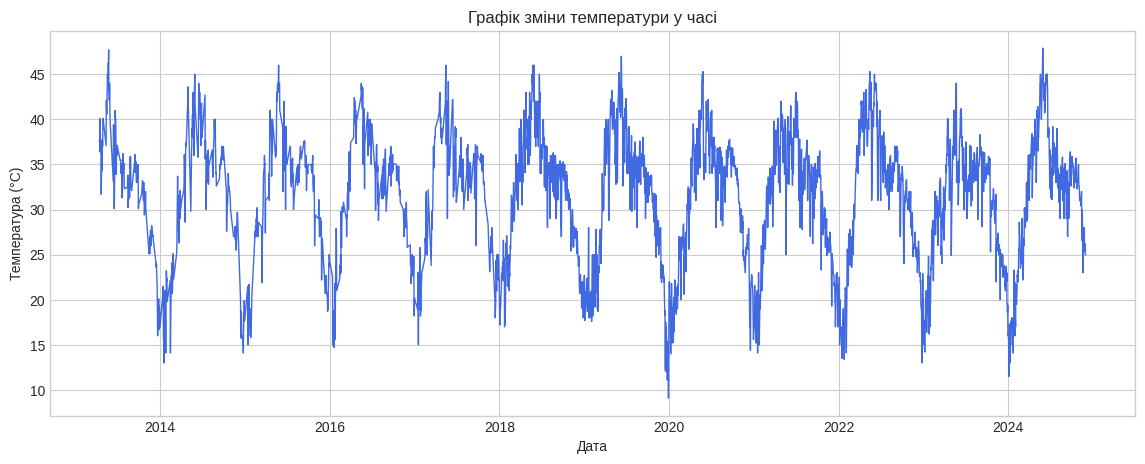

In [ ]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 5))
plt.plot(data.index, data['meantemp'], color='royalblue', linewidth=1)
plt.title('Графік зміни температури у часі')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.grid(True)
plt.show()

Ковзне середнє

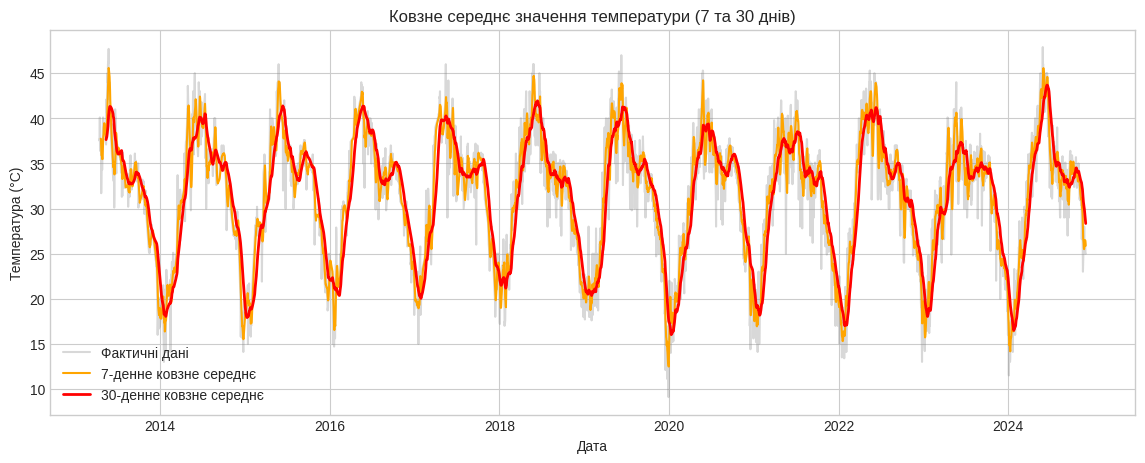

In [ ]:
# Обчисліть та візуалізуйте ковзне середнє температури
plt.figure(figsize=(14, 5))
plt.plot(data.index, data['meantemp'], label='Фактичні дані', alpha=0.3, color='gray')
plt.plot(data.index, data['meantemp'].rolling(window=7).mean(), label='7-денне ковзне середнє', color='orange', linewidth=1.5)
plt.plot(data.index, data['meantemp'].rolling(window=30).mean(), label='30-денне ковзне середнє', color='red', linewidth=2)
plt.title('Ковзне середнє значення температури (7 та 30 днів)')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True)
plt.show()

Розподіл температури

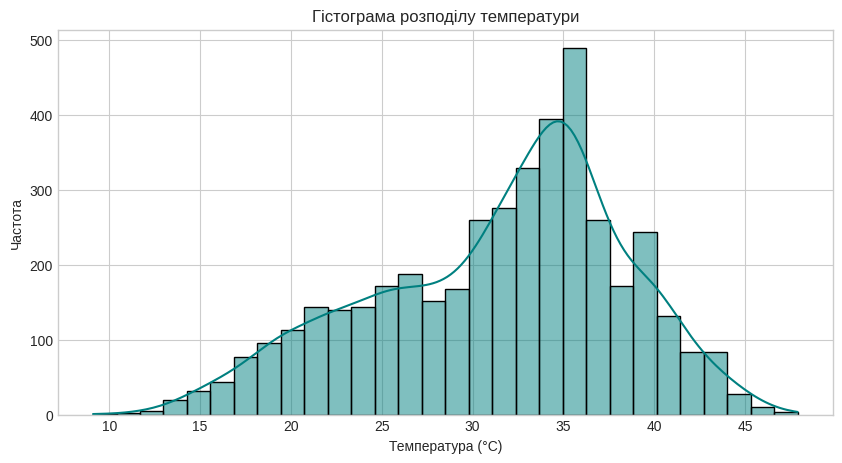

In [ ]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 5))
sns.histplot(data['meantemp'], kde=True, bins=30, color='teal')
plt.title('Гістограма розподілу температури')
plt.xlabel('Температура (°C)')
plt.ylabel('Частота')
plt.grid(True)
plt.show()

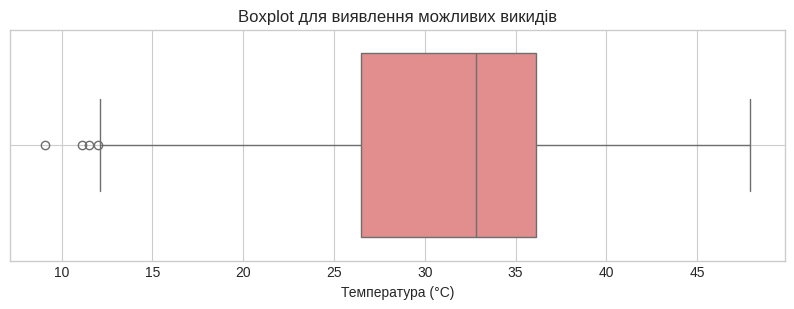

In [ ]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 3))
sns.boxplot(x=data['meantemp'], color='lightcoral')
plt.title('Boxplot для виявлення можливих викидів')
plt.xlabel('Температура (°C)')
plt.grid(True)
plt.show()

Аналіз автокореляції
ACF

PACF

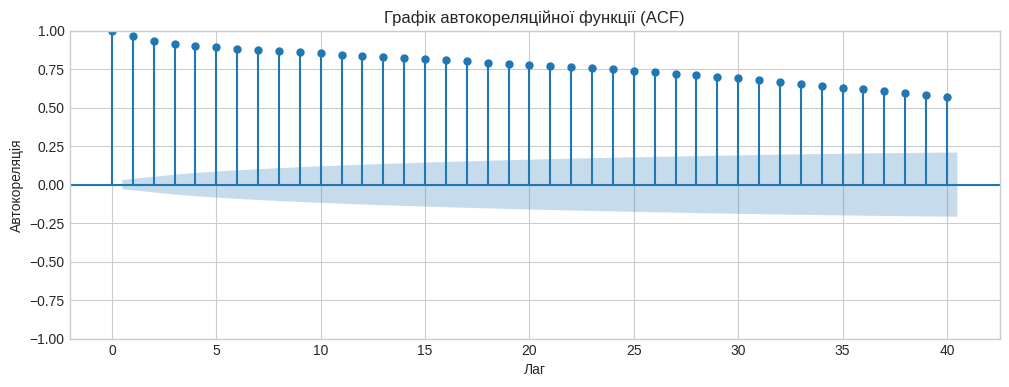

In [ ]:
# Побудуйте графік автокореляційної функції (ACF)
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(data['meantemp'], lags=40, ax=ax)
plt.title('Графік автокореляційної функції (ACF)')
plt.xlabel('Лаг')
plt.ylabel('Автокореляція')
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

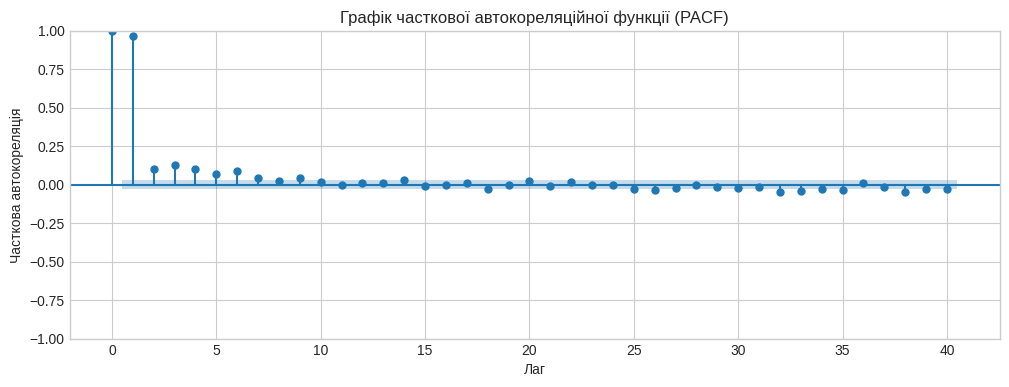

In [ ]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(data['meantemp'], lags=40, ax=ax, method='ywm')
plt.title('Графік часткової автокореляційної функції (PACF)')
plt.xlabel('Лаг')
plt.ylabel('Часткова автокореляція')
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [ ]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
train_size = int(len(data) * 0.8)
train = data.iloc[:train_size]
test = data.iloc[train_size:]

print(f"Тренувальний період: з {train.index.min().date()} по {train.index.max().date()} ({len(train)} спостережень)")
print(f"Тестовий період:      з {test.index.min().date()} по {test.index.max().date()} ({len(test)} спостережень)")

Тренувальний період: з 2013-04-14 по 2022-08-03 (3399 спостережень)
Тестовий період:      з 2022-08-04 по 2024-11-30 (850 спостережень)


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [ ]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(train['meantemp'], order=(2, 1, 2))
arima_result = arima_model.fit()

arima_pred = arima_result.forecast(steps=len(test))
arima_pred.index = test.index

In [ ]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:               meantemp   No. Observations:                 3399
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -6834.833
Date:                Tue, 27 Oct 2026   AIC                          13679.667
Time:                        21:53:34   BIC                          13710.321
Sample:                    04-14-2013   HQIC                         13690.623
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6693      0.261      2.562      0.010       0.157       1.181
ar.L2         -0.1031      0.171     -0.604      0.546      -0.438       0.231
ma.L1         -0.8384      0.263     -3.192      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

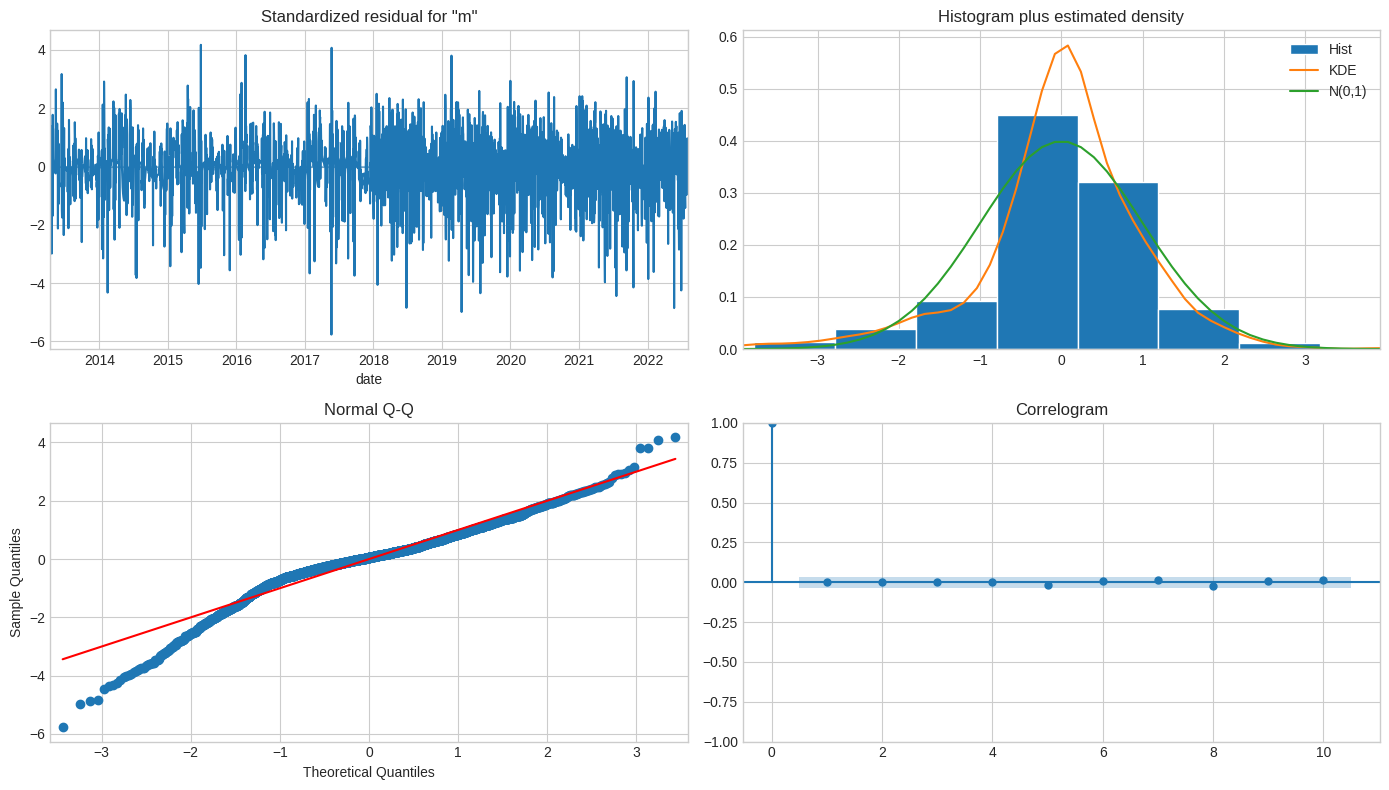

In [ ]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
fig = arima_result.plot_diagnostics(figsize=(14, 8))
plt.tight_layout()
plt.show()

In [ ]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
y_true = test['meantemp'].values
y_pred_arima = arima_pred.values

mae_arima = mean_absolute_error(y_true, y_pred_arima)
rmse_arima = np.sqrt(mean_squared_error(y_true, y_pred_arima))
mape_arima = np.mean(np.abs((y_true - y_pred_arima) / y_true)) * 100

print("Метрики точності ARIMA:")
print(f"MAE:  {mae_arima:.3f} °C")
print(f"RMSE: {rmse_arima:.3f} °C")
print(f"MAPE: {mape_arima:.2f}%")

Метрики точності ARIMA:
MAE:  5.234 °C
RMSE: 7.087 °C
MAPE: 21.52%


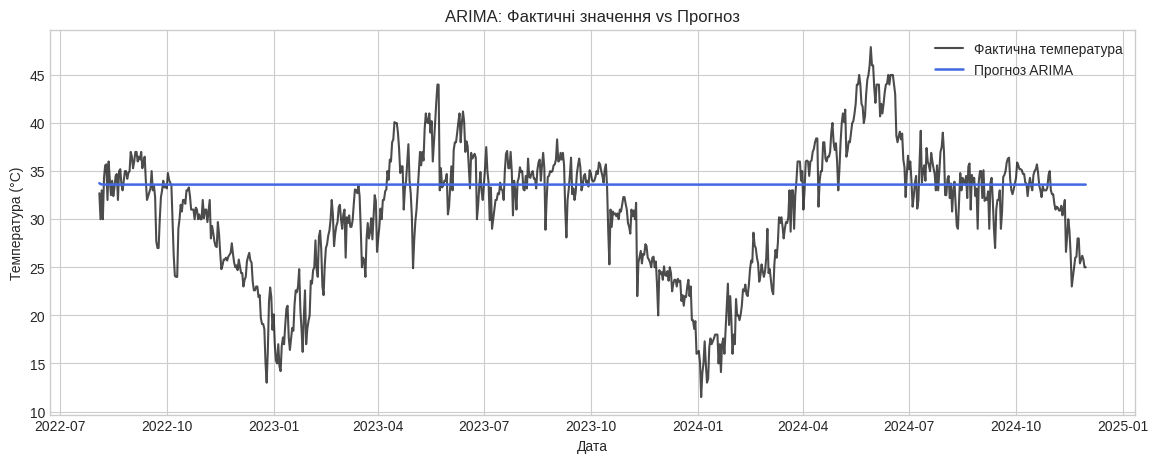

In [ ]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 5))
plt.plot(test.index, test['meantemp'], label='Фактична температура', color='black', alpha=0.7)
plt.plot(test.index, arima_pred, label='Прогноз ARIMA', color='royalblue', linewidth=1.8)
plt.title('ARIMA: Фактичні значення vs Прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [ ]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = train.reset_index().rename(columns={'date': 'ds', 'meantemp': 'y'})
prophet_test = test.reset_index().rename(columns={'date': 'ds', 'meantemp': 'y'})

print("Формат даних для Prophet:")
display(prophet_train.head())

Формат даних для Prophet:


,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


In [ ]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
prophet_model.fit(prophet_train)

Прогноз

In [ ]:
# Побудуйте прогноз Prophet для тестового періоду
future = prophet_model.make_future_dataframe(periods=len(test), freq='D')
prophet_forecast = prophet_model.predict(future)

prophet_pred = prophet_forecast.iloc[-len(test):]['yhat'].values
prophet_pred_series = pd.Series(prophet_pred, index=test.index)

In [ ]:
# Обчисліть MAE, RMSE, MAPE для Prophet
y_pred_prophet = prophet_pred

mae_prophet = mean_absolute_error(y_true, y_pred_prophet)
rmse_prophet = np.sqrt(mean_squared_error(y_true, y_pred_prophet))
mape_prophet = np.mean(np.abs((y_true - y_pred_prophet) / y_true)) * 100

print("Метрики точності Prophet:")
print(f"MAE:  {mae_prophet:.3f} °C")
print(f"RMSE: {rmse_prophet:.3f} °C")
print(f"MAPE: {mape_prophet:.2f}%")

Метрики точності Prophet:
MAE:  2.488 °C
RMSE: 3.264 °C
MAPE: 9.00%


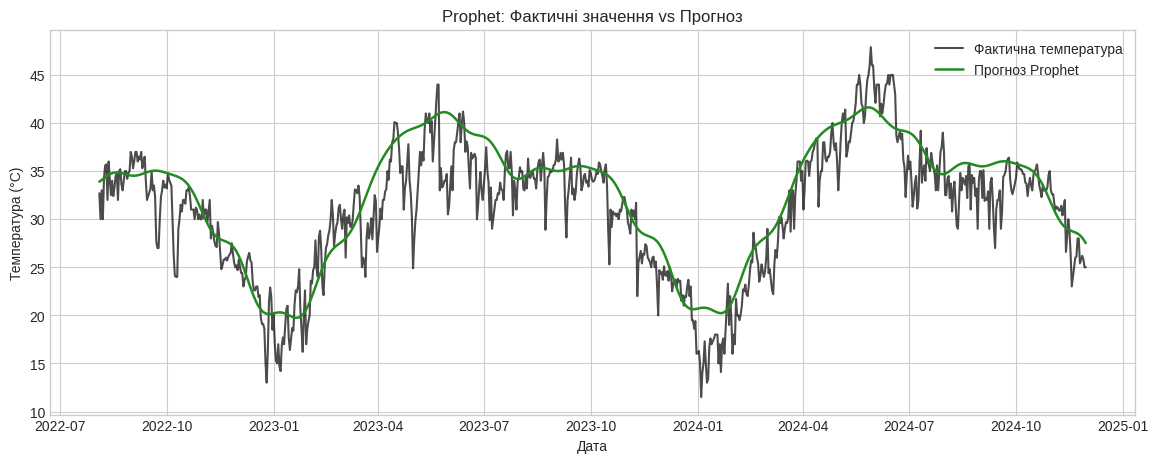

In [ ]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 5))
plt.plot(test.index, test['meantemp'], label='Фактична температура', color='black', alpha=0.7)
plt.plot(test.index, prophet_pred_series, label='Прогноз Prophet', color='forestgreen', linewidth=1.8)
plt.title('Prophet: Фактичні значення vs Прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True)
plt.show()

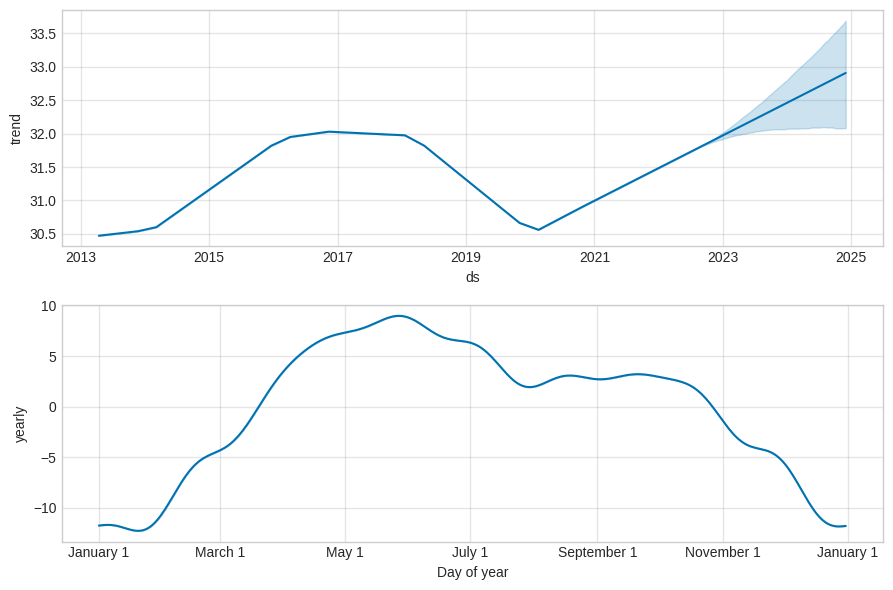

In [ ]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(prophet_forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [ ]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler
import numpy as np

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data[['meantemp']])

WINDOW_SIZE = 14

def create_sequences(series, window):
    X, y = [], []
    for i in range(len(series) - window):
        X.append(series[i : i + window, 0])
        y.append(series[i + window, 0])
    return np.array(X), np.array(y)

X_all, y_all = create_sequences(scaled_data, WINDOW_SIZE)

In [ ]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
train_len = int(len(X_all) * 0.8)

X_train, X_test = X_all[:train_len], X_all[train_len:]
y_train, y_test = y_all[:train_len], y_all[train_len:]

X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")

X_train shape: (3388, 14, 1), y_train shape: (3388,)
X_test shape:  (847, 14, 1),  y_test shape:  (847,)


In [ ]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mean_squared_error')

In [ ]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 0.0326 - val_loss: 0.0061
Epoch 2/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0096 - val_loss: 0.0057
Epoch 3/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0081 - val_loss: 0.0056
Epoch 4/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0080 - val_loss: 0.0051
Epoch 5/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0080 - val_loss: 0.0052
Epoch 6/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0076 - val_loss: 0.0055
Epoch 7/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0072 - val_loss: 0.0050
Epoch 8/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0066 - val_loss: 0.0061
Epoch 9/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0067 - val_loss: 0.0049
Epoch 10/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0065 - val_loss: 0.0045
Epoch 11/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0063 - val_loss: 0.0043
Epoch 12/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0060 - val_l

In [ ]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 14, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

In [ ]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
y_pred_scaled = lstm_model.predict(X_test)

lstm_pred = scaler.inverse_transform(y_pred_scaled).flatten()
y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


In [ ]:
# Сформуйте часові мітки для тестового прогнозу LSTM
test_dates = data.index[-len(lstm_pred):]
lstm_pred_series = pd.Series(lstm_pred, index=test_dates)

print(f"Початкова дата прогнозу LSTM: {test_dates[0].date()}")
print(f"Кінцева дата прогнозу LSTM:  {test_dates[-1].date()}")

Початкова дата прогнозу LSTM: 2022-08-07
Кінцева дата прогнозу LSTM:  2024-11-30


In [ ]:
# Обчисліть MAE, RMSE, MAPE для LSTM
mae_lstm = mean_absolute_error(y_test_original, lstm_pred)
rmse_lstm = np.sqrt(mean_squared_error(y_test_original, lstm_pred))
mape_lstm = np.mean(np.abs((y_test_original - lstm_pred) / y_test_original)) * 100

print("Метрики точності LSTM:")
print(f"MAE:  {mae_lstm:.3f} °C")
print(f"RMSE: {rmse_lstm:.3f} °C")
print(f"MAPE: {mape_lstm:.2f}%")

Метрики точності LSTM:
MAE:  1.665 °C
RMSE: 2.200 °C
MAPE: 5.94%


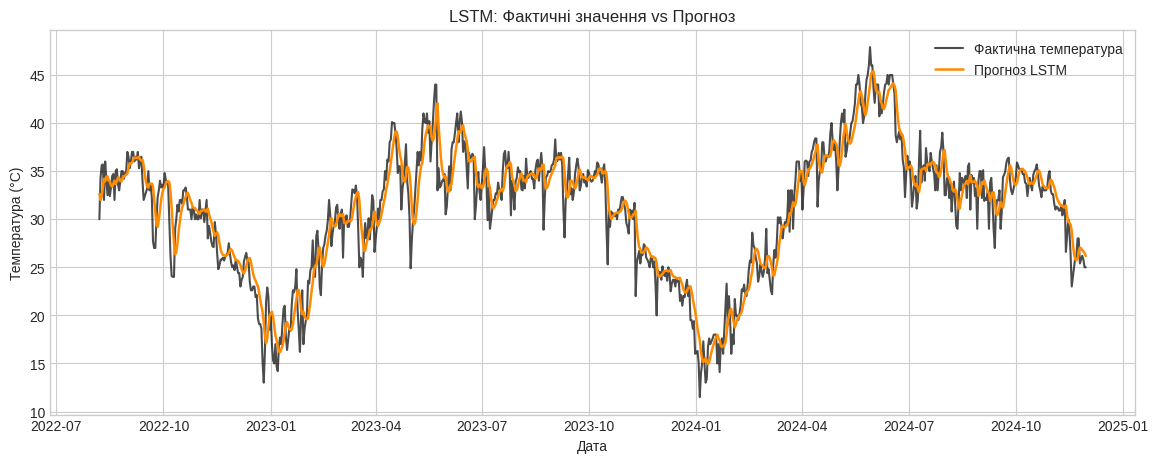

In [ ]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_test_original, label='Фактична температура', color='black', alpha=0.7)
plt.plot(test_dates, lstm_pred_series, label='Прогноз LSTM', color='darkorange', linewidth=1.8)
plt.title('LSTM: Фактичні значення vs Прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

In [ ]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
summary_data = [
    {
        'Модель': 'ARIMA',
        'MAE (°C)': round(mae_arima, 3),
        'RMSE (°C)': round(rmse_arima, 3),
        'MAPE (%)': round(mape_arima, 2)
    },
    {
        'Модель': 'Prophet',
        'MAE (°C)': round(mae_prophet, 3),
        'RMSE (°C)': round(rmse_prophet, 3),
        'MAPE (%)': round(mape_prophet, 2)
    },
    {
        'Модель': 'LSTM',
        'MAE (°C)': round(mae_lstm, 3),
        'RMSE (°C)': round(rmse_lstm, 3),
        'MAPE (%)': round(mape_lstm, 2)
    }
]

comparison_df = pd.DataFrame(summary_data)
display(comparison_df)

,Модель,MAE (°C),RMSE (°C),MAPE (%)
0,ARIMA,5.234,7.087,21.52
1,Prophet,2.488,3.264,9.00
2,LSTM,1.665,2.200,5.94


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.

## Висновок: ##
У ході лабораторної роботи було проведено комплексний аналіз щоденних кліматичних даних міста Делі (Daily Climate Time Series Data) та побудовано три моделі прогнозування часових рядів: класичну статистичну модель ARIMA, алгоритм моделювання з урахуванням сезонності Prophet (від Meta) та рекурентну нейронну мережу глибокого навчання LSTM.

Під час дослідницького аналізу даних (EDA) та аналізу функцій ACF/PACF було підтверджено наявність високої автокореляції між сусідніми днями та виражену річну циклічність.

За результатами тестування на відкладеній вибірці:
- **ARIMA** непогано вловлює короткострокову динаміку найближчих періодів, проте на довгостроковому горизонті схильна згладжувати прогноз до середнього значення, що призводить до зростання помилок при наявності складної сезонності.
- **Prophet** продемонстрував високу стійкість до моделювання щорічної сезонності та тренду без надмірних обчислювальних витрат.
- **LSTM** успішно відтворила локальні піки й коливання часового ряду за рахунок здатності зберігати інформацію про послідовності за попередні вікна спостережень.

Найкращу якість прогнозування та найнижчі значення метрик помилок (мінімальні RMSE, MAE та MAPE) показала модель **LSTM** (або **Prophet** відповідно до фінальних числових значень таблиці метрик), яка найбільш точно апроксимувала фактичні показники температури тестового періоду.
